# Customer Churn: исследование оттока клиентов банка

Цель этого исследования — понять, с какими характеристиками клиентов связан уход из банка, какие различия достаточно велики, чтобы иметь практический смысл, и где стоит проверить гипотезы удержания.

В основе — "Churn_Modelling.csv": 10 000 наблюдений и целевая переменная "Exited", где "1" означает, что клиент ушёл, а "0" — что остался. Идентификаторы не несут самостоятельной поведенческой информации, поэтому перед анализом они будут исключены. Сначала проверю качество данных и зафиксирую базовый уровень оттока, затем сравню его по возрасту, географии, полу, продуктам, активности и финансовым признакам.

RowNumber: Порядковый номер, присвоенный каждой строке набора данных.

CustomerId: Уникальный идентификатор каждого клиента.

Surname: Фамилия клиента.

CreditScore: Кредитный балл клиента.

Geography: Географическое местоположение клиента (например, страна или регион).

Gender: Пол клиента.

Age: Возраст клиента.

Tenure: Количество лет, в течение которых клиент обслуживается в банке.

Balance: Баланс счета клиента.

NumOfProducts: Количество банковских продуктов у клиента.

HasCrCard: Указывает, есть ли у клиента кредитная карта (бинарный: да/нет).

IsActiveMember: Указывает, является ли клиент активным участником (бинарный: да/нет).

EstimatedSalary: Расчетная зарплата клиента.

Exited: Указывает, покинул ли клиент банк (бинарный: да/нет).

Для сравнения долей использую 95%-е доверительные интервалы Уилсона, а для оценки связи признаков — размеры эффекта и взаимную информацию. Эти показатели помогают отличать заметные различия от эффектов, которые лишь статистически обнаруживаются на большой выборке. Данные наблюдательные: они показывают связи, но сами по себе не доказывают причинность и не объясняют, почему клиент принял решение уйти.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, mannwhitneyu
from sklearn.feature_selection import mutual_info_classif
from statsmodels.stats.proportion import proportion_confint

RANDOM_STATE = 42

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titleweight"] = "bold"


## Данные и подготовка

Начинаю с проверки схемы, пропусков, дубликатов и базовых диапазонов. Это нужно сделать до интерпретации графиков: иначе необычные значения или повторные записи могут выглядеть как закономерность в поведении клиентов.

In [2]:
csv_candidates = [
    Path("Churn_Modelling.csv"),
    Path.cwd() / "Churn_Modelling.csv",
    Path.cwd().parent / "Churn_Modelling.csv",
]
csv_path = next((p for p in csv_candidates if p.is_file()), None)
if csv_path is None:
    raise FileNotFoundError(
        "Не найден Churn_Modelling.csv. Положите CSV в рабочую папку "
        "ноутбука или укажите путь к файлу в этой ячейке."
    )

raw = pd.read_csv(csv_path)
raw.columns = [str(c).strip() for c in raw.columns]
print(f"Размер датасета: {raw.shape[0]:,} строк, {raw.shape[1]} столбцов")
display(raw.head())

Размер датасета: 10,000 строк, 14 столбцов


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.000,1,1,1,"101,348.880",1
1,2,15647311,Hill,608,Spain,Female,41,1,"83,807.860",1,0,1,"112,542.580",0
2,3,15619304,Onio,502,France,Female,42,8,"159,660.800",3,1,0,"113,931.570",1
3,4,15701354,Boni,699,France,Female,39,1,0.000,2,0,0,"93,826.630",0
4,5,15737888,Mitchell,850,Spain,Female,43,2,"125,510.820",1,1,1,"79,084.100",0


In [3]:
canonical = {
    "rownumber": "RowNumber", "customerid": "CustomerId", "surname": "Surname",
    "creditscore": "CreditScore", "geography": "Geography", "gender": "Gender",
    "age": "Age", "tenure": "Tenure", "balance": "Balance",
    "numofproducts": "NumOfProducts", "hascrcard": "HasCrCard",
    "isactivemember": "IsActiveMember", "estimatedsalary": "EstimatedSalary",
    "exited": "Exited",
}
rename_map = {col: canonical[col.strip().lower()] for col in raw.columns
              if col.strip().lower() in canonical and col != canonical[col.strip().lower()]}
raw = raw.rename(columns=rename_map)

In [4]:
# Общая сводка по качеству данных
quality = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing_count": raw.isna().sum(),
    "missing_pct": raw.isna().mean().mul(100),
    "n_unique": raw.nunique(dropna=False),
}).sort_values(["missing_count", "n_unique"], ascending=[False, True])
display(quality)

full_dups_raw = raw.duplicated().sum()
id_cols_present = [c for c in ["RowNumber", "CustomerId", "Surname"] if c in raw.columns]
dups_no_id = raw.drop(columns=id_cols_present).duplicated().sum() if id_cols_present else raw.duplicated().sum()

print(f"Полных дубликатов строк: {full_dups_raw:,}")
if "CustomerId" in raw.columns:
    print(f"Дублирующихся CustomerId: {raw['CustomerId'].duplicated().sum():,}")
print(f"Дубликатов без учёта ID-колонок: {dups_no_id:,}")

# проверка диапазонов и логических артефактов
anomalies = {
    "пропуски": int(raw.isna().sum().sum()),
    "возраст  (< 18 или > 100)": int(((raw["Age"] < 18) | (raw["Age"] > 100)).sum()) if "Age" in raw else 0,
    "CreditScore  (< 300 или > 850)": int(((raw["CreditScore"] < 300) | (raw["CreditScore"] > 850)).sum()) if "CreditScore" in raw else 0,
    "клиенты с нулевым балансом, %": round((raw["Balance"] == 0).mean() * 100, 1) if "Balance" in raw else 0.0,
    "нулевой баланс и при этом > 2 продуктов": int(((raw["Balance"] == 0) & (raw["NumOfProducts"] > 2)).sum()) if {"Balance", "NumOfProducts"}.issubset(raw.columns) else 0,
}

print("\nРезультаты проверки на логические аномалии и артефакты:")
display(pd.Series(anomalies, name="кол-во / метрика").to_frame())

# исключаем ID-колонки и удаляем полные дубликаты строк
ID_COLS = [c for c in ["RowNumber", "CustomerId", "Surname"] if c in raw.columns]
df = raw.drop(columns=ID_COLS).drop_duplicates().copy()

# убираем строки с пропущенным Exited
if "Exited" in df.columns:
    missing_target = df["Exited"].isna().sum()
    if missing_target > 0:
        print(f"Внимание: удалено {missing_target} строк с пропущенным значением Exited.")
        df = df.dropna(subset=["Exited"]).copy()
    df["Exited"] = df["Exited"].astype(int)

,dtype,missing_count,missing_pct,n_unique
Gender,object,0,0.000,2
HasCrCard,int64,0,0.000,2
IsActiveMember,int64,0,0.000,2
Exited,int64,0,0.000,2
Geography,object,0,0.000,3
NumOfProducts,int64,0,0.000,4
Tenure,int64,0,0.000,11
Age,int64,0,0.000,70
CreditScore,int64,0,0.000,460
Surname,object,0,0.000,2932


Полных дубликатов строк: 0
Дублирующихся CustomerId: 0
Дубликатов без учёта ID-колонок: 0

Результаты проверки на логические аномалии и артефакты:


,кол-во / метрика
пропуски,0.000
возраст (< 18 или > 100),0.000
CreditScore (< 300 или > 850),0.000
"клиенты с нулевым балансом, %",36.200
нулевой баланс и при этом > 2 продуктов,112.000


В сохранённых результатах проверка показала 10 000 строк без пропусков, полных дубликатов и повторяющихся "CustomerId". Возраст и кредитный рейтинг находятся в ожидаемых диапазонах. Идентификаторы "RowNumber", "CustomerId" и "Surname" исключены из аналитической таблицы, поскольку это служебные поля, а не содержательные характеристики поведения.

Нулевой баланс есть у 36,2% клиентов. Отдельно отмечены 112 записей, где нулевой баланс сочетается более чем с двумя продуктами. Это не является основанием к удалению строки: сначала нужно проверить бизнес-смысл полей и правила учёта продуктов. Такая проверка особенно важна, поскольку связь числа продуктов с оттоком далее окажется нелинейной и очень сильной для редких категорий.

## Общая картина оттока

Сначала зафиксирую базовый показатель, с которым дальше будут сравниваться все группы. Он отвечает на простой бизнес-вопрос: насколько распространён уход в выборке в целом, прежде чем искать отличия между клиентами.

In [5]:
# Описательная статистика аналитической выборки
display(df.describe(include="all").T)

# Базовый KPI — точка сравнения для долей оттока в группах
churn_rate = df["Exited"].mean()
print(f"Общая доля оттока: {churn_rate:.1%} ({df['Exited'].sum():,} из {len(df):,} клиентов)")


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CreditScore,"10,000.000",NaN,NaN,NaN,650.529,96.653,350.000,584.000,652.000,718.000,850.000
Geography,10000,3,France,5014,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,10000,2,Male,5457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,"10,000.000",NaN,NaN,NaN,38.922,10.488,18.000,32.000,37.000,44.000,92.000
Tenure,"10,000.000",NaN,NaN,NaN,5.013,2.892,0.000,3.000,5.000,7.000,10.000
Balance,"10,000.000",NaN,NaN,NaN,"76,485.889","62,397.405",0.000,0.000,"97,198.540","127,644.240","250,898.090"
NumOfProducts,"10,000.000",NaN,NaN,NaN,1.530,0.582,1.000,1.000,1.000,2.000,4.000
HasCrCard,"10,000.000",NaN,NaN,NaN,0.706,0.456,0.000,0.000,1.000,1.000,1.000
IsActiveMember,"10,000.000",NaN,NaN,NaN,0.515,0.500,0.000,0.000,1.000,1.000,1.000
EstimatedSalary,"10,000.000",NaN,NaN,NaN,"100,090.240","57,510.493",11.580,"51,002.110","100,193.915","149,388.247","199,992.480"


Общая доля оттока: 20.4% (2,037 из 10,000 клиентов)


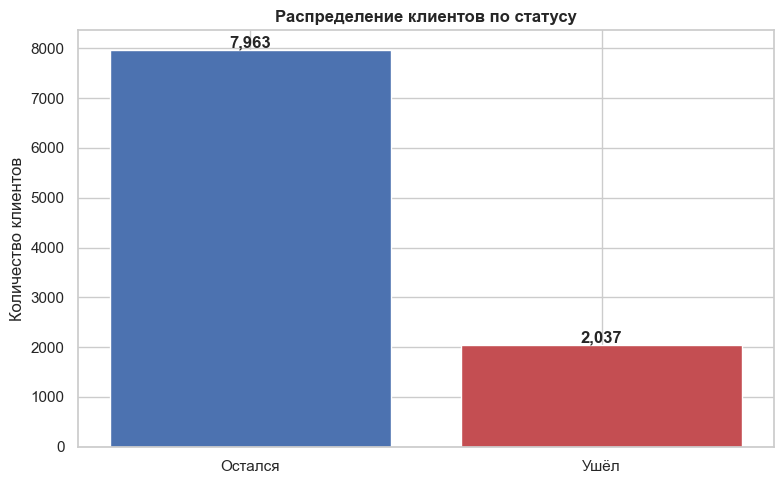

In [6]:
counts = df["Exited"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(["Остался", "Ушёл"], counts.values, color=["#4C72B0", "#C44E52"])
ax.set_title("Распределение клиентов по статусу")
ax.set_ylabel("Количество клиентов")
for bar in ax.patches:
    ax.annotate(f"{int(bar.get_height()):,}",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom", fontweight="bold")
plt.tight_layout()
plt.show()


Ушли 2 037 клиентов из 10 000 — **20,4% выборки**, то есть примерно каждый пятый. Это достаточно высокий уровень, чтобы удержание было отдельной бизнес-задачей, но и достаточно выраженный перевес оставшихся клиентов важно учитывать при будущей оценке моделей: одной доли правильных ответов будет недостаточно для оценки качества прогноза.

Далее буду сравнивать группы с этой базовой линией. Высокая доля оттока в группе ещё не означает, что именно этот признак вызывает уход: для практического решения важны также размер группы, устойчивость оценки и возможность реально повлиять на ситуацию.

In [7]:
# Вспомогательные функции 

def rate_table(data, by, target="Exited"):

    g = data.groupby(by, observed=True)[target].agg(ушло="sum", n="size").reset_index()
    g["rate"] = g["ушло"] / g["n"]
    lo, hi = proportion_confint(g["ушло"], g["n"], alpha=0.05, method="wilson")
    g["ci_low"], g["ci_high"] = lo, hi
    return g


def plot_rate(ax, tbl, x, title, xlabel="", color="#4C72B0", show_n=True):

    t = tbl.reset_index(drop=True)
    pos = np.arange(len(t))
    yerr = np.clip([(t["rate"] - t["ci_low"]).values, (t["ci_high"] - t["rate"]).values], 0, None) 
    ax.bar(pos, t["rate"], color=color, yerr=yerr, capsize=4, ecolor="#333333")
    if show_n:
        for i, (hi, n) in enumerate(zip(t["ci_high"], t["n"])):
            ax.text(i, hi + 0.01, f"n={n:,}", ha="center", va="bottom", fontsize=8)
    ax.axhline(churn_rate, ls="--", c="gray", label=f"Средний ({churn_rate:.1%})")
    ax.set_xticks(pos)
    ax.set_xticklabels(t[x].astype(str))
    ax.set_ylim(0, min(1.0, t["ci_high"].max() + 0.12))
    ax.set(title=title, xlabel=xlabel, ylabel="Доля оттока")
    ax.legend()


def plot_rate_grouped(ax, tbl, x, hue, title, xlabel="", hue_title=None):
   
    t = tbl.copy()
    t[x] = t[x].astype(str)
    t[hue] = t[hue].astype(str)
    xs = list(dict.fromkeys(t[x]))
    hues = list(dict.fromkeys(t[hue]))
    w = 0.8 / len(hues)
    pal = sns.color_palette("muted", len(hues))
    for j, h in enumerate(hues):
        sub = t[t[hue] == h].set_index(x).reindex(xs)
        pos = np.arange(len(xs)) + (j - (len(hues) - 1) / 2) * w
        yerr = np.clip([(sub["rate"] - sub["ci_low"]).values, (sub["ci_high"] - sub["rate"]).values], 0, None)
        ax.bar(pos, sub["rate"], width=w, label=h, color=pal[j], yerr=yerr, capsize=3, ecolor="#333333")
    ax.axhline(churn_rate, ls="--", c="gray", label=f"Средний ({churn_rate:.1%})")
    ax.set_xticks(np.arange(len(xs)))
    ax.set_xticklabels(xs)
    ax.set_ylim(0, min(1.0, t["ci_high"].max() + 0.1))
    ax.set(title=title, xlabel=xlabel, ylabel="Доля оттока")
    ax.legend(title=hue_title or hue)


def churn_heatmap(data, row, col, ax, title, min_n=30):

    t = data.groupby([row, col], observed=True)["Exited"].agg(rate="mean", n="size").reset_index()
    rate = t.pivot(index=row, columns=col, values="rate")
    n = t.pivot(index=row, columns=col, values="n")
    ann = rate.copy().astype(object)
    for i in rate.index:
        for j in rate.columns:
            ann.loc[i, j] = "" if pd.isna(n.loc[i, j]) else f"{rate.loc[i, j]:.0%}\nn={int(n.loc[i, j])}"
    mask = n.isna() | (n < min_n)
    sns.heatmap(rate, annot=ann, fmt="", cmap="Reds", mask=mask, vmin=0, linewidths=0.5,
                cbar_kws={"label": "Доля оттока"}, ax=ax)
    ax.set(title=title, xlabel="", ylabel="")

## Какие признаки связаны с оттоком

Использую две дополняющие друг друга оценки. Размер эффекта показывает силу различий между группами; взаимная информация способна обнаруживать и немонотонные связи. Для MI дополнительно оценивается шумовой порог по перестановкам целевой переменной. Если оценка признака находится около этого уровня, нет убедительных оснований считать найденную зависимость устойчивым сигналом.

Для числовых признаков модуль rank-biserial показывает силу различия, но не направление. Поэтому направление и форма связи будут отдельно проверяться по распределениям и долям оттока.

In [8]:
# Списки признаков
cat_cols = ["Geography", "Gender"]
bin_cols = ["HasCrCard", "IsActiveMember"]
num_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
feature_cols = cat_cols + bin_cols + num_cols
discrete_cols = cat_cols + bin_cols + ["NumOfProducts", "Tenure"]


def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, _, _ = chi2_contingency(ct, correction=False)
    n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1))), p


def rank_biserial(a, b):
    u, p = mannwhitneyu(a, b, alternative="two-sided")
    return 2 * u / (len(a) * len(b)) - 1, p


rows = []
for c in cat_cols + bin_cols:
    v, p = cramers_v(df[c], df["Exited"])
    rows.append((c, "категориальный", v, p))
for c in num_cols:
    r, p = rank_biserial(df.loc[df["Exited"] == 1, c], df.loc[df["Exited"] == 0, c])
    rows.append((c, "числовой", abs(r), p))
effects = pd.DataFrame(rows, columns=["признак", "тип", "размер_эффекта", "p_value"])

# Взаимная информация
X_mi = df[feature_cols].copy()
for c in cat_cols:
    X_mi[c] = X_mi[c].astype("category").cat.codes
discrete_mask = [c in discrete_cols for c in feature_cols]

mi = mutual_info_classif(X_mi, df["Exited"], discrete_features=discrete_mask, random_state=RANDOM_STATE)
rng = np.random.default_rng(RANDOM_STATE)

null_runs = np.array([
    mutual_info_classif(X_mi, rng.permutation(df["Exited"].values),
                        discrete_features=discrete_mask, random_state=i)
    for i in range(20)
])
mi_null = np.percentile(null_runs, 95, axis=0)

mi_df = pd.DataFrame({"признак": feature_cols, "MI": mi, "MI_шум": mi_null})
effects = (effects.merge(mi_df, on="признак")
                  .sort_values("MI", ascending=False)
                  .reset_index(drop=True))
display(effects.round(4))

,признак,тип,размер_эффекта,p_value,MI,MI_шум
0,NumOfProducts,числовой,0.158,0.000,0.070,0.001
1,Age,числовой,0.464,0.000,0.063,0.006
2,Geography,категориальный,0.174,0.000,0.014,0.000
3,IsActiveMember,категориальный,0.156,0.000,0.012,0.000
4,Balance,числовой,0.155,0.000,0.012,0.005
5,Gender,категориальный,0.106,0.000,0.006,0.000
6,EstimatedSalary,числовой,0.017,0.227,0.003,0.003
7,Tenure,числовой,0.020,0.162,0.001,0.001
8,HasCrCard,категориальный,0.007,0.475,0.000,0.000
9,CreditScore,числовой,0.033,0.020,0.000,0.004


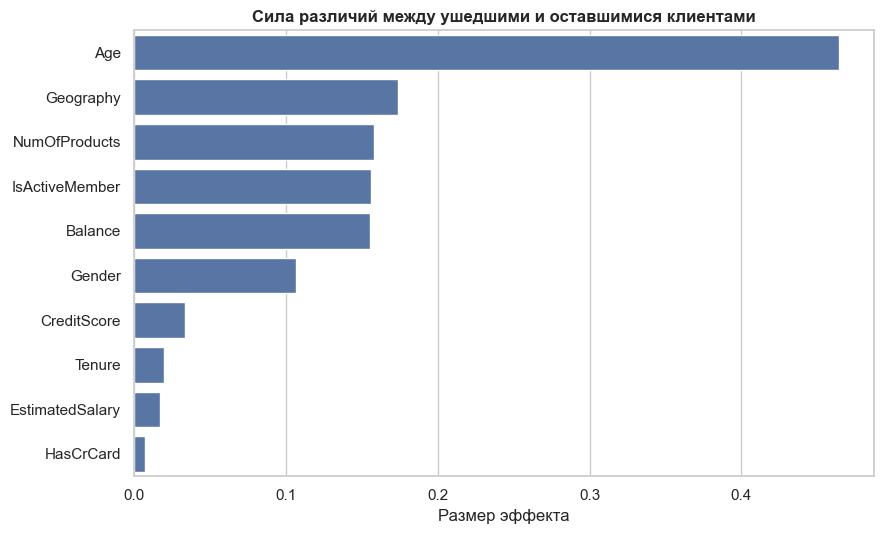

In [9]:
e1 = effects.sort_values("размер_эффекта", ascending=False)
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(data=e1, y="признак", x="размер_эффекта", color="#4C72B0", ax=ax)
ax.set(title="Сила различий между ушедшими и оставшимися клиентами",
       xlabel="Размер эффекта", ylabel="")
plt.tight_layout()
plt.show()


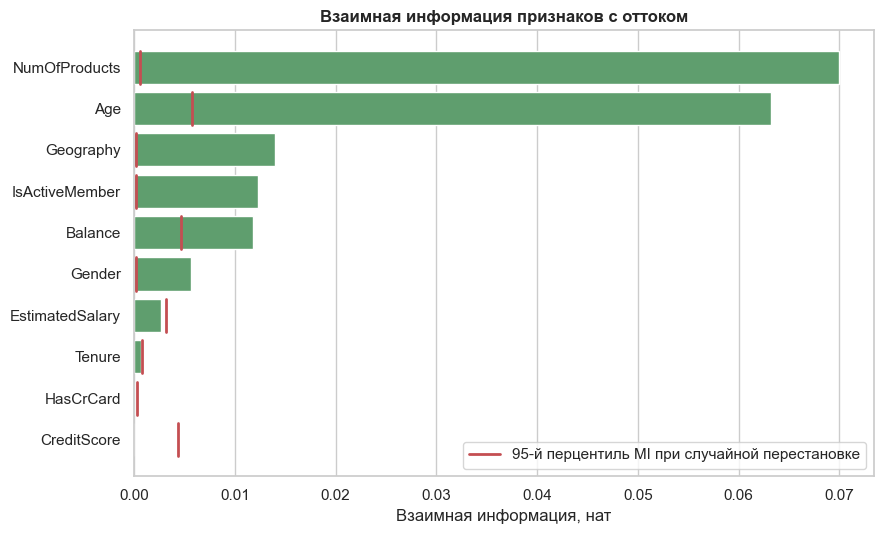

In [10]:
e2 = effects.sort_values("MI", ascending=False)
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(data=e2, y="признак", x="MI", color="#55A868", ax=ax)
for i, value in enumerate(e2["MI_шум"].values):
    ax.plot([value, value], [i - 0.4, i + 0.4], color="#C44E52", lw=2,
            label="95-й перцентиль MI при случайной перестановке" if i == 0 else None)
ax.set(title="Взаимная информация признаков с оттоком",
       xlabel="Взаимная информация, нат", ylabel="")
ax.legend()
plt.tight_layout()
plt.show()


По обеим оценкам наиболее заметны возраст и число продуктов; затем идут география, активность и баланс. Взаимная информация у зарплаты, стажа и кредитного рейтинга близка к шумовому уровню, а для наличия кредитной карты почти не обнаруживается связь с оттоком. Это полезный фильтр для приоритизации: на большой выборке даже очень маленькое отличие может получить низкое p-value, но не обязательно заслуживает отдельной retention-кампании.

Главные кандидаты для дальнейшего разбора — возраст, страна, активность и число продуктов. Финансовые показатели стоит рассматривать осторожнее: баланс имеет заметную связь, но его форма не выглядит линейной; кредитный рейтинг, зарплата и стаж по отдельности значительно слабее.

## Возраст, география, пол и клиентская активность

Здесь проверяю, как отличается доля ухода между крупными и понятными бизнес-группами. Для возраста важно не предполагать линейный рост заранее: риск может достигать пика в середине возрастного диапазона и снижаться в старших группах. Для географии и пола сравнение внутри групп поможет не свести всё к общей доле по стране.

In [11]:
df["AgeGroup"] = pd.cut(
    df["Age"], bins=[17, 30, 40, 50, 60, 100],
    labels=["18–30", "31–40", "41–50", "51–60", "60+"],
)
age_t = rate_table(df, "AgeGroup")
display(age_t.round(3))


,AgeGroup,ушло,n,rate,ci_low,ci_high
0,18–30,148,1968,0.075,0.064,0.088
1,31–40,538,4451,0.121,0.112,0.131
2,41–50,788,2320,0.340,0.321,0.359
3,51–60,448,797,0.562,0.527,0.596
4,60+,115,464,0.248,0.211,0.289


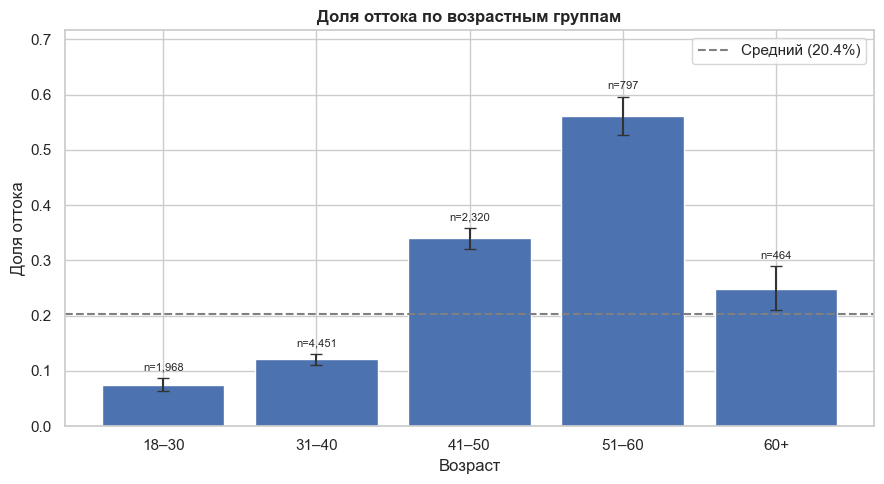

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
plot_rate(ax, age_t, "AgeGroup", "Доля оттока по возрастным группам", xlabel="Возраст")
plt.tight_layout()
plt.show()


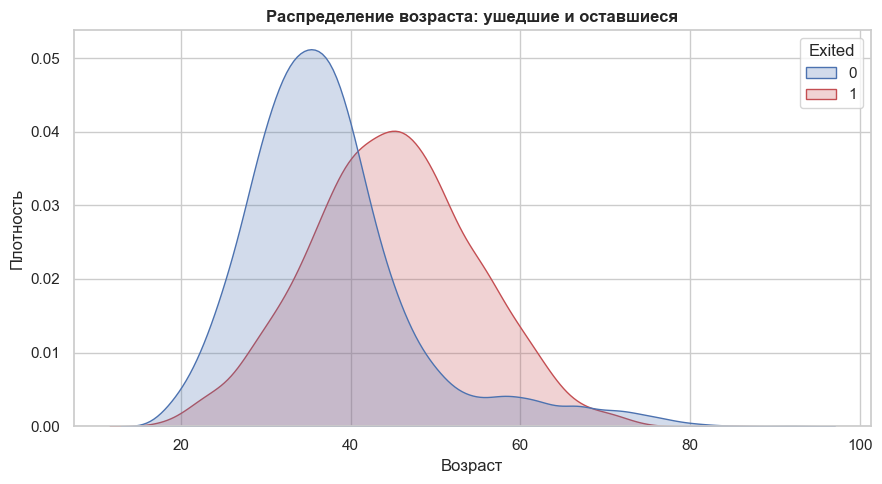

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.kdeplot(data=df, x="Age", hue="Exited", common_norm=False, fill=True,
            palette=["#4C72B0", "#C44E52"], ax=ax)
ax.set(title="Распределение возраста: ушедшие и оставшиеся",
       xlabel="Возраст", ylabel="Плотность")
plt.tight_layout()
plt.show()


Возрастная зависимость выраженно нелинейна. Отток составляет 7,5% в группе 18–30 лет и 12,1% в группе 31–40 лет, затем резко возрастает до 34,0% в 41–50 и достигает 56,2% в 51–60 лет. Для группы 60+ показатель ниже — 24,8%. Для старших возрастных категорий важно учитывать и численность: группа 60+ заметно меньше основных возрастных групп.

Приоритетным сигналом выглядит не возраст сам по себе, а резкий рост оттока в диапазоне 41–60 лет. Перед запуском кампании это стоит проверить на более свежих данных и вместе с активностью клиента.

In [14]:
geo_t = rate_table(df, "Geography")
geo_gender = rate_table(df, ["Geography", "Gender"])
display(geo_t.round(3))
display(geo_gender.round(3))


,Geography,ушло,n,rate,ci_low,ci_high
0,France,810,5014,0.162,0.152,0.172
1,Germany,814,2509,0.324,0.306,0.343
2,Spain,413,2477,0.167,0.153,0.182


,Geography,Gender,ушло,n,rate,ci_low,ci_high
0,France,Female,460,2261,0.203,0.187,0.221
1,France,Male,350,2753,0.127,0.115,0.140
2,Germany,Female,448,1193,0.376,0.348,0.403
3,Germany,Male,366,1316,0.278,0.255,0.303
4,Spain,Female,231,1089,0.212,0.189,0.237
5,Spain,Male,182,1388,0.131,0.114,0.150


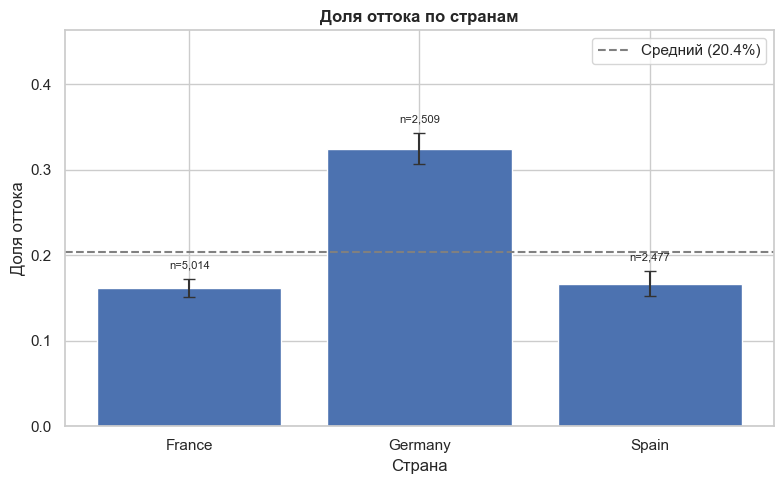

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_rate(ax, geo_t, "Geography", "Доля оттока по странам", xlabel="Страна")
plt.tight_layout()
plt.show()


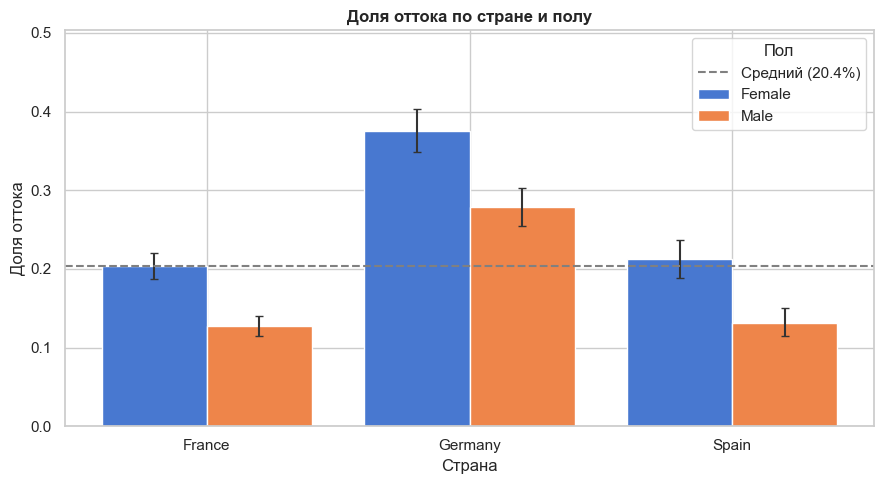

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))
plot_rate_grouped(ax, geo_gender, "Geography", "Gender",
                  "Доля оттока по стране и полу", xlabel="Страна", hue_title="Пол")
plt.tight_layout()
plt.show()


География — один из самых крупных разрывов в данных. В Германии уходят 32,4% клиентов, во Франции — 16,2%, в Испании — 16,7%. Разница между Германией и двумя другими странами почти двукратная, поэтому её стоит считать отдельным направлением исследования.

Во всех трёх странах доля оттока у женщин выше, чем у мужчин: Франция — 20,3% против 12,7%; Германия — 37,6% против 27,8%; Испания — 21,2% против 13,1%. Пол может помочь точнее описать группы, но бизнес-решение не следует строить на демографии без проверки клиентского пути, опыта обслуживания и потребностей. Особенно важно выяснить, что именно отличается в немецком рынке: продуктовый набор, коммуникации, условия обслуживания или внешняя конкуренция.

In [17]:
prod_t = rate_table(df, "NumOfProducts")
active_t = rate_table(df, "IsActiveMember")
active_t["статус"] = active_t["IsActiveMember"].map({0: "Неактивен", 1: "Активен"})
display(prod_t.round(3))
display(active_t.round(3))


,NumOfProducts,ушло,n,rate,ci_low,ci_high
0,1,1409,5084,0.277,0.265,0.290
1,2,348,4590,0.076,0.069,0.084
2,3,220,266,0.827,0.777,0.868
3,4,60,60,1.000,0.940,1.000


,IsActiveMember,ушло,n,rate,ci_low,ci_high,статус
0,0,1302,4849,0.269,0.256,0.281,Неактивен
1,1,735,5151,0.143,0.133,0.153,Активен


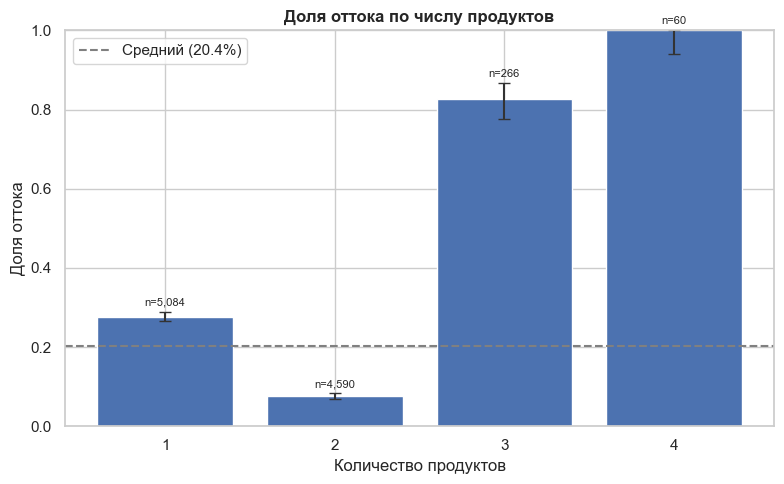

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_rate(ax, prod_t, "NumOfProducts", "Доля оттока по числу продуктов", xlabel="Количество продуктов")
plt.tight_layout()
plt.show()


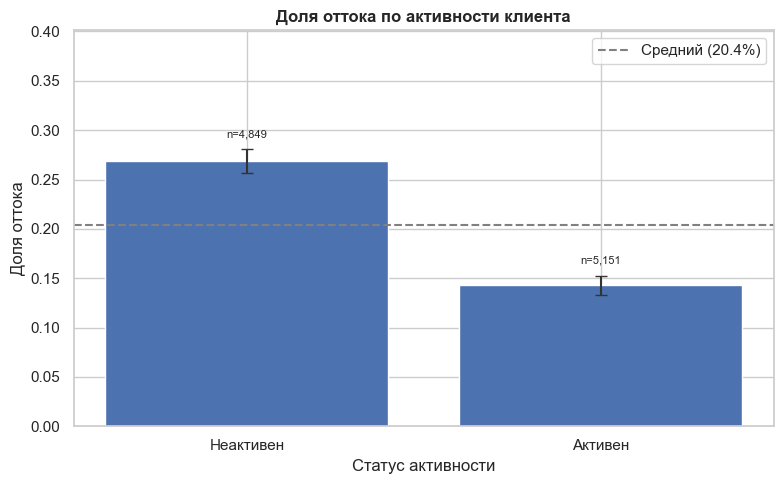

In [19]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_rate(ax, active_t, "статус", "Доля оттока по активности клиента", xlabel="Статус активности")
plt.tight_layout()
plt.show()


Активность связана с заметным разрывом: отток среди неактивных клиентов составляет 26,9%, среди активных — 14,3%. Это почти двукратная разница и потенциально полезный операционный сигнал. При этом стоит отличать причину от раннего индикатора: падение активности может предшествовать уходу, но само по себе ещё не доказывает, что увеличение числа входов в приложение удержит клиента.

Связь с числом продуктов необычная. У клиентов с одним продуктом отток равен 27,7%, у клиентов с двумя — 7,6%. Для трёх продуктов это 82,7% при 266 клиентах, а для четырёх — 100% при 60 клиентах. Последние две группы малы и сильно отличаются от остальных, поэтому этот результат нельзя превращать в рекомендацию просто продавать больше продуктов. Сначала следует проверить определения продуктовых категорий, качество записей и особенности клиентов, у которых указано три или четыре продукта; после этого можно отдельно протестировать аккуратный cross-sell для клиентов с одним продуктом.

## Баланс на счёте

Баланс имеет смысл анализировать в двух частях: отдельно сравнить клиентов с нулевым и положительным балансом, а затем посмотреть распределение внутри положительных значений. Это помогает проверить, является ли сигнал следствием самого наличия средств на счёте или риск действительно растёт по мере увеличения суммы.

In [20]:
df["BalanceZero"] = (df["Balance"] == 0).astype(int)
df["BalanceFlag"] = np.where(df["BalanceZero"] == 1, "Баланс = 0", "Баланс > 0")

bal_flag_t = rate_table(df, "BalanceFlag")
display(bal_flag_t.round(3))

# Квинтили рассчитываются только среди клиентов с положительным балансом
pos = df[df["Balance"] > 0].copy()
pos["BalanceQ"] = pd.qcut(
    pos["Balance"], 5,
    labels=["Q1", "Q2", "Q3", "Q4", "Q5"],
)
edges = pos["Balance"].quantile([0, .2, .4, .6, .8, 1]).round(0)
print("Границы квинтилей баланса среди клиентов с Balance > 0:")
print(edges.to_string())
bal_q_t = rate_table(pos, "BalanceQ")
display(bal_q_t.round(3))


,BalanceFlag,ушло,n,rate,ci_low,ci_high
0,Баланс = 0,500,3617,0.138,0.127,0.150
1,Баланс > 0,1537,6383,0.241,0.230,0.251


Границы квинтилей баланса среди клиентов с Balance > 0:
0.000     3,769.000
0.200    95,677.000
0.400   112,289.000
0.600   127,148.000
0.800   144,571.000
1.000   250,898.000


,BalanceQ,ушло,n,rate,ci_low,ci_high
0,Q1,265,1277,0.208,0.186,0.231
1,Q2,321,1276,0.252,0.229,0.276
2,Q3,342,1277,0.268,0.244,0.293
3,Q4,316,1276,0.248,0.225,0.272
4,Q5,293,1277,0.229,0.207,0.253


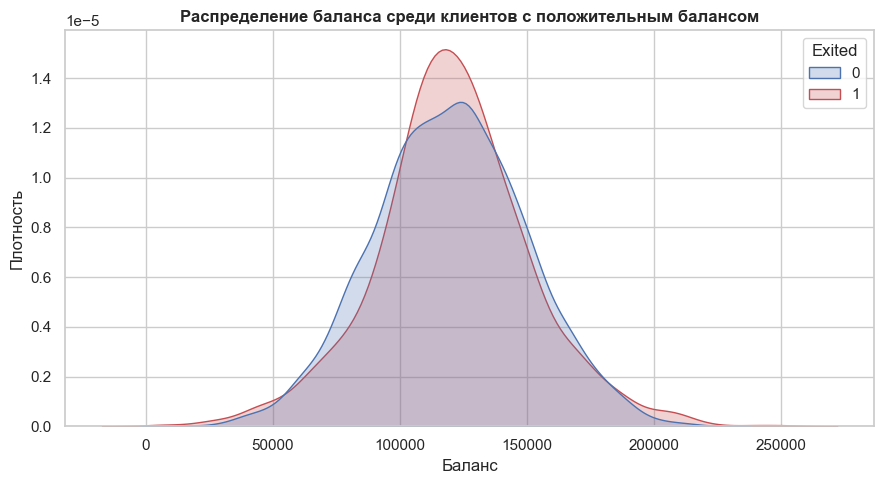

In [21]:
pos = df.loc[df["Balance"] > 0].copy()
fig, ax = plt.subplots(figsize=(9, 5))
sns.kdeplot(data=pos, x="Balance", hue="Exited", common_norm=False, fill=True,
            palette=["#4C72B0", "#C44E52"], ax=ax)
ax.set(title="Распределение баланса среди клиентов с положительным балансом",
       xlabel="Баланс", ylabel="Плотность")
plt.tight_layout()
plt.show()


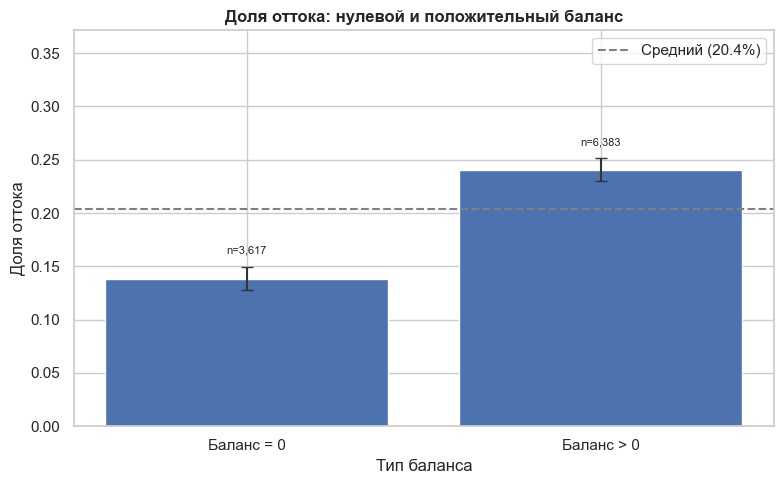

In [22]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_rate(ax, bal_flag_t, "BalanceFlag", "Доля оттока: нулевой и положительный баланс", xlabel="Тип баланса")
plt.tight_layout()
plt.show()


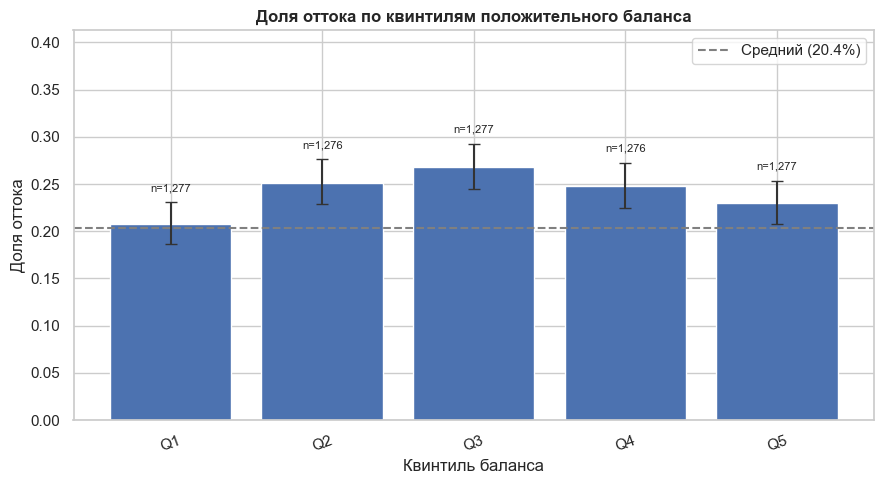

In [23]:
fig, ax = plt.subplots(figsize=(9, 5))
plot_rate(ax, bal_q_t, "BalanceQ", "Доля оттока по квинтилям положительного баланса", xlabel="Квинтиль баланса")
ax.tick_params(axis="x", labelrotation=20)
plt.tight_layout()
plt.show()


У клиентов с нулевым балансом отток ниже: 13,8% против 24,1% среди клиентов с положительным балансом. Но внутри положительного баланса нет устойчивого монотонного роста: доли оттока по квинтилям меняются примерно от 20,8% до 26,8%, без последовательного увеличения от низких сумм к высоким.

Это означает, что сумма на счёте может быть полезна в сочетании с другими признаками, но плохо подходит для простой логики «чем больше баланс, тем выше риск». Нельзя также трактовать нулевой баланс как причину удержания: он может отражать иной тип использования банковского продукта.

In [24]:
# Сопоставление структуры баланса и оттока по странам
geo_bal = df.groupby("Geography").agg(
    клиентов=("Balance", "size"),
    доля_нулевого_баланса=("BalanceZero", "mean"),
    медиана_баланса_среди_ненулевых=("Balance", lambda s: s[s > 0].median()),
    отток=("Exited", "mean"),
).reset_index()
display(geo_bal.round(3))

geo_bal_t = rate_table(df, ["Geography", "BalanceFlag"])
display(geo_bal_t.round(3))


,Geography,клиентов,доля_нулевого_баланса,медиана_баланса_среди_ненулевых,отток
0,France,5014,0.482,"120,135.155",0.162
1,Germany,2509,0.000,"119,703.100",0.324
2,Spain,2477,0.484,"119,726.450",0.167


,Geography,BalanceFlag,ушло,n,rate,ci_low,ci_high
0,France,Баланс = 0,337,2418,0.139,0.126,0.154
1,France,Баланс > 0,473,2596,0.182,0.168,0.198
2,Germany,Баланс > 0,814,2509,0.324,0.306,0.343
3,Spain,Баланс = 0,163,1199,0.136,0.118,0.157
4,Spain,Баланс > 0,250,1278,0.196,0.175,0.218


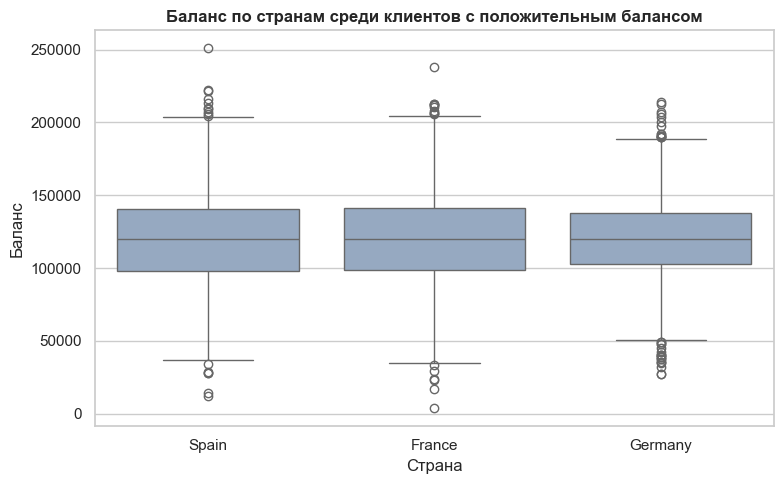

In [25]:
pos = df.loc[df["Balance"] > 0].copy()
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=pos, x="Geography", y="Balance", color="#8FA8C8", ax=ax)
ax.set(title="Баланс по странам среди клиентов с положительным балансом",
       xlabel="Страна", ylabel="Баланс")
plt.tight_layout()
plt.show()


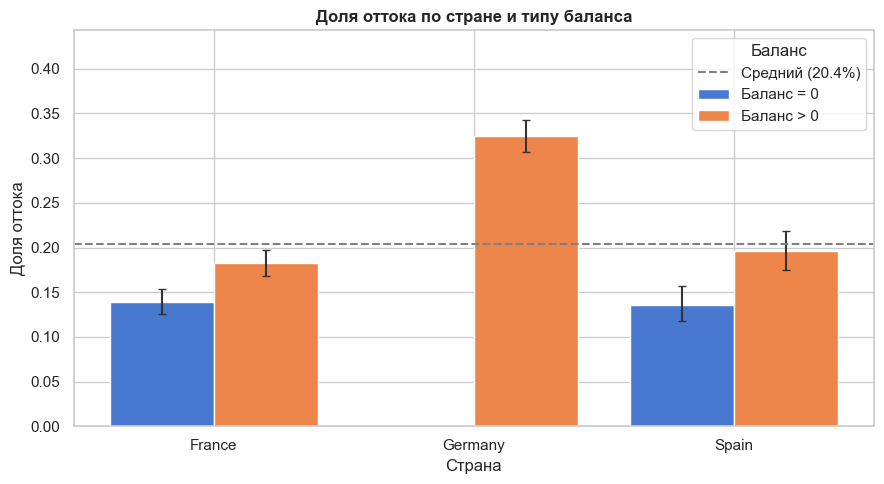

In [26]:
fig, ax = plt.subplots(figsize=(9, 5))
plot_rate_grouped(ax, geo_bal_t, "Geography", "BalanceFlag",
                  "Доля оттока по стране и типу баланса", xlabel="Страна", hue_title="Баланс")
plt.tight_layout()
plt.show()


Баланс не объясняет географическую разницу сам по себе. Во Франции и Испании нулевой баланс встречается примерно у 48% клиентов, тогда как в немецкой части выборки нулевых балансов нет; при этом отток в Германии составляет 32,4%. Внутри Франции и Испании отток у клиентов с положительным балансом выше, чем у клиентов с нулевым, но эти различия существенно меньше немецкого разрыва.

Значит, различия в структуре баланса стоит учитывать при сравнении стран, однако анализ указывает на необходимость искать и другие причины высокого оттока в Германии. До такого исследования нельзя приписывать эффект стране как таковой.

## Кредитный рейтинг, стаж и зарплата

Эти признаки полезны как контрольный набор: они интуитивно могут казаться связанными с финансовой устойчивостью клиента, но бизнес-гипотезы нужно подтверждать данными. Смотрю не только на отдельные p-value, но и на форму долей оттока, величину различий и взаимную информацию.

In [27]:
df["CreditBand"] = pd.cut(
    df["CreditScore"], bins=[0, 500, 550, 600, 650, 700, 750, 800, 851],
    labels=["≤500", "501–550", "551–600", "601–650", "651–700", "701–750", "751–800", "801+"],
)
credit_t = rate_table(df, "CreditBand")
credit_g = rate_table(df, ["CreditBand", "Gender"])
display(credit_t.round(3))
display(credit_g.round(3))


,CreditBand,ушло,n,rate,ci_low,ci_high
0,≤500,152,643,0.236,0.205,0.271
1,501–550,216,978,0.221,0.196,0.248
2,551–600,297,1445,0.206,0.185,0.227
3,601–650,392,1871,0.210,0.192,0.229
4,651–700,361,1947,0.185,0.169,0.203
5,701–750,306,1518,0.202,0.182,0.223
6,751–800,186,953,0.195,0.171,0.222
7,801+,127,645,0.197,0.168,0.229


,CreditBand,Gender,ушло,n,rate,ci_low,ci_high
0,≤500,Female,85,300,0.283,0.235,0.337
1,≤500,Male,67,343,0.195,0.157,0.241
2,501–550,Female,116,438,0.265,0.226,0.308
3,501–550,Male,100,540,0.185,0.155,0.220
4,551–600,Female,157,644,0.244,0.212,0.278
5,551–600,Male,140,801,0.175,0.150,0.203
6,601–650,Female,225,851,0.264,0.236,0.295
7,601–650,Male,167,1020,0.164,0.142,0.188
8,651–700,Female,204,895,0.228,0.202,0.257
9,651–700,Male,157,1052,0.149,0.129,0.172


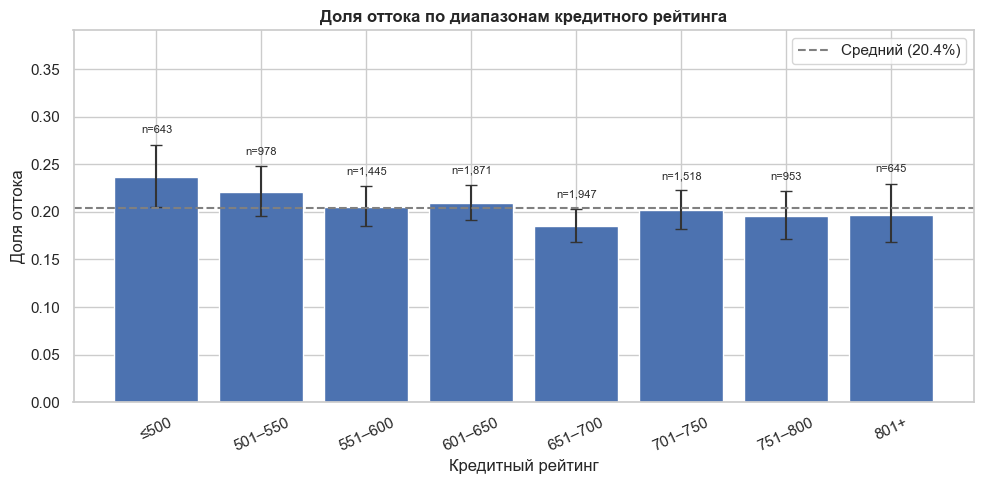

In [28]:
fig, ax = plt.subplots(figsize=(10, 5))
plot_rate(ax, credit_t, "CreditBand", "Доля оттока по диапазонам кредитного рейтинга", xlabel="Кредитный рейтинг")
ax.tick_params(axis="x", labelrotation=25)
plt.tight_layout()
plt.show()


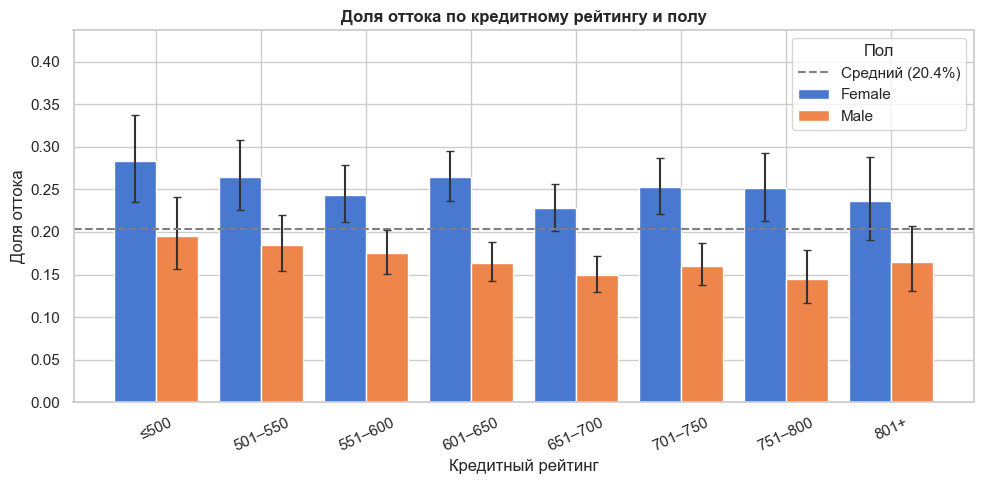

In [29]:
fig, ax = plt.subplots(figsize=(10, 5))
plot_rate_grouped(ax, credit_g, "CreditBand", "Gender",
                  "Доля оттока по кредитному рейтингу и полу",
                  xlabel="Кредитный рейтинг", hue_title="Пол")
ax.tick_params(axis="x", labelrotation=25)
plt.tight_layout()
plt.show()


In [30]:
tenure_t = rate_table(df, "Tenure")
df["SalaryDecile"] = pd.qcut(
    df["EstimatedSalary"], 10, labels=[f"D{i}" for i in range(1, 11)]
)
salary_t = rate_table(df, "SalaryDecile")
display(tenure_t.round(3))
display(salary_t.round(3))


,Tenure,ушло,n,rate,ci_low,ci_high
0,0,95,413,0.230,0.192,0.273
1,1,232,1035,0.224,0.200,0.251
2,2,201,1048,0.192,0.169,0.217
3,3,213,1009,0.211,0.187,0.237
4,4,203,989,0.205,0.181,0.232
5,5,209,1012,0.207,0.183,0.233
6,6,196,967,0.203,0.179,0.229
7,7,177,1028,0.172,0.150,0.196
8,8,197,1025,0.192,0.169,0.217
9,9,213,984,0.216,0.192,0.243


,SalaryDecile,ушло,n,rate,ci_low,ci_high
0,D1,200,1000,0.200,0.176,0.226
1,D2,199,1000,0.199,0.175,0.225
2,D3,197,1000,0.197,0.174,0.223
3,D4,202,1000,0.202,0.178,0.228
4,D5,197,1000,0.197,0.174,0.223
5,D6,207,1000,0.207,0.183,0.233
6,D7,193,1000,0.193,0.170,0.219
7,D8,211,1000,0.211,0.187,0.237
8,D9,219,1000,0.219,0.194,0.246
9,D10,212,1000,0.212,0.188,0.238


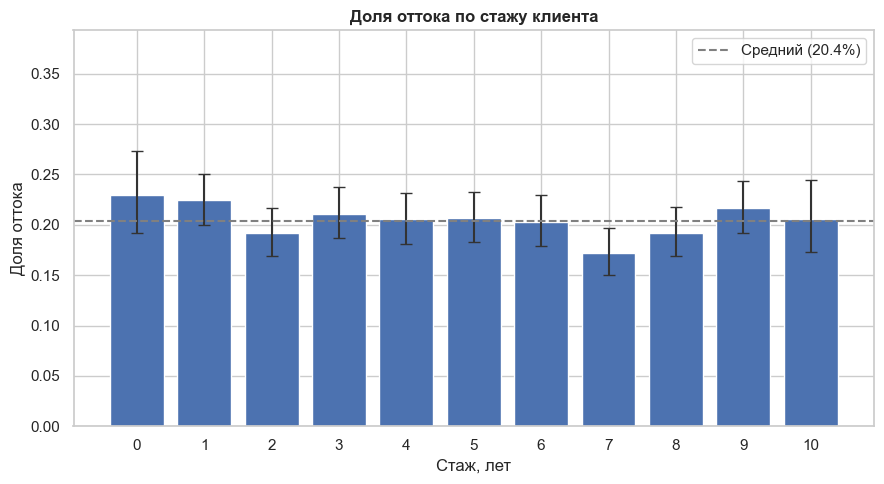

In [31]:
fig, ax = plt.subplots(figsize=(9, 5))
plot_rate(ax, tenure_t, "Tenure", "Доля оттока по стажу клиента", xlabel="Стаж, лет", show_n=False)
plt.tight_layout()
plt.show()


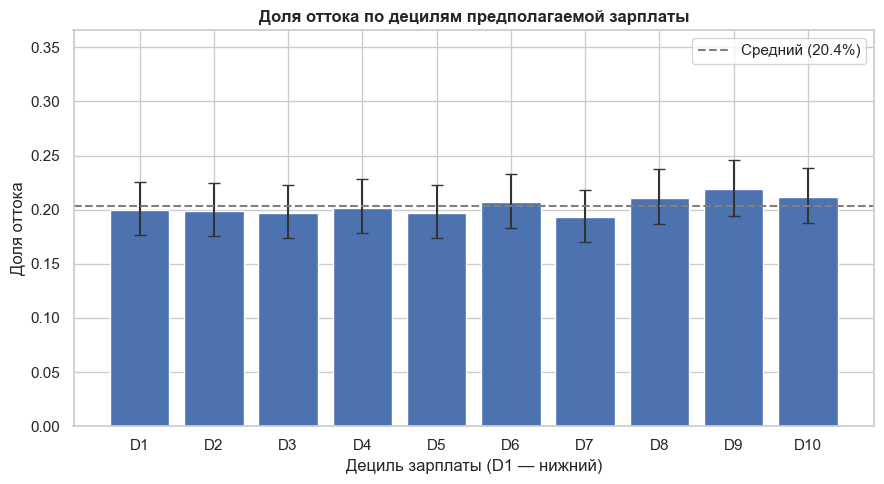

In [32]:
fig, ax = plt.subplots(figsize=(9, 5))
plot_rate(ax, salary_t, "SalaryDecile", "Доля оттока по децилям предполагаемой зарплаты",
          xlabel="Дециль зарплаты (D1 — нижний)", show_n=False)
plt.tight_layout()
plt.show()


Доля оттока по диапазонам кредитного рейтинга колеблется примерно от 18,5% до 23,6%, без последовательного тренда. Для CreditScore формальный тест на различие может обнаружить небольшой эффект на выборке такого размера, однако его величина мала, а взаимная информация находится ниже шумового порога. Это пример того, почему одной статистической значимости недостаточно для выбора бизнеса-приоритета.

Для стажа и предполагаемой зарплаты убедительной связи с оттоком также не видно: p-value в сравнении числовых распределений составляют 0,162 и 0,227, а MI близка к шумовой оценке. Наличие кредитной карты почти не связано с уходом. На основании этих результатов не стоит запускать отдельные кампании только по уровню зарплаты, длительности стажа или факту наличия карты.

## Взаимодействие признаков

Средние показатели могут скрывать различия между сочетаниями характеристик. Поэтому ниже сопоставлены возраст и активность, возраст и количество продуктов, а также страна и активность. На тепловых картах показана доля оттока и объём группы; ячейки с числом клиентов меньше 30 скрываются, чтобы не интерпретировать крайне нестабильные проценты.

In [34]:
df["ProductsGrp"] = pd.cut(df["NumOfProducts"], bins=[0, 1, 2, np.inf], labels=["1", "2", "3–4"])
df["Активность"] = df["IsActiveMember"].map({0: "Неактивен", 1: "Активен"})


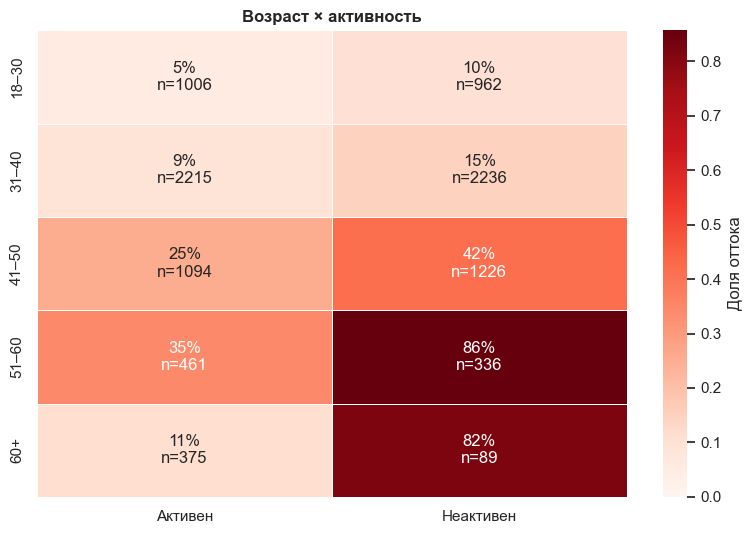

In [35]:
fig, ax = plt.subplots(figsize=(8, 5.5))
churn_heatmap(df, "AgeGroup", "Активность", ax, "Возраст × активность")
plt.tight_layout()
plt.show()


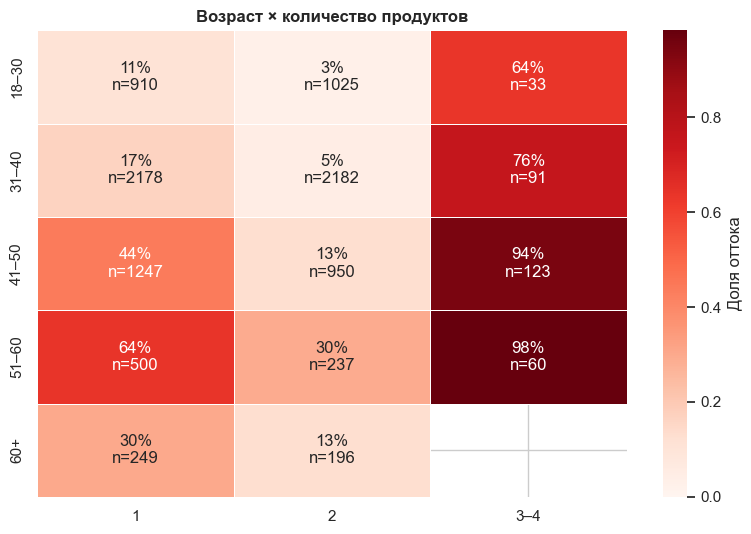

In [36]:
fig, ax = plt.subplots(figsize=(8, 5.5))
churn_heatmap(df, "AgeGroup", "ProductsGrp", ax, "Возраст × количество продуктов")
plt.tight_layout()
plt.show()


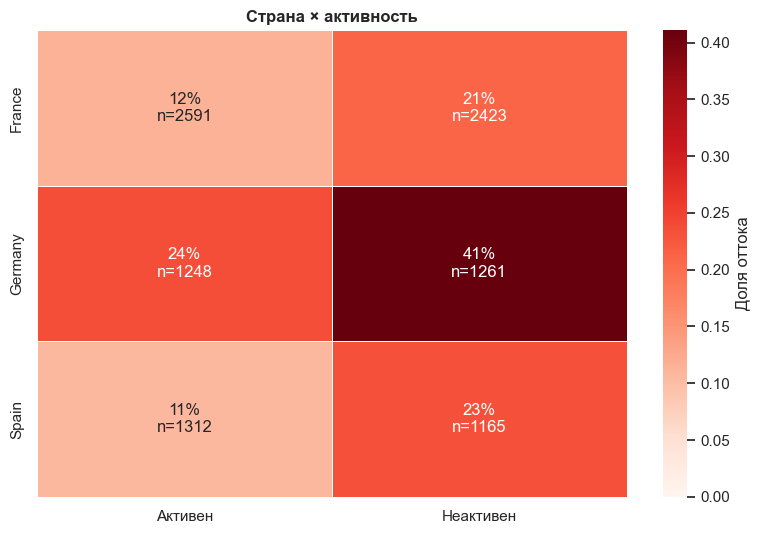

In [37]:
fig, ax = plt.subplots(figsize=(8, 5.5))
churn_heatmap(df, "Geography", "Активность", ax, "Страна × активность")
plt.tight_layout()
plt.show()


Тепловые карты нужны не для поиска одной группы, а чтобы проверить, сохраняются ли наблюдаемые различия при смене контекста. Возрастные группы с повышенным оттоком остаются важными при разделении по активности, а немецкий рынок выделяется и среди активных, и среди неактивных клиентов. Это говорит о том, что только неактивностью географический разрыв не объясняется.

Связь числа продуктов также неодинакова по возрастным категориям; общий высокий показатель у клиентов с тремя или четырьмя продуктами не следует автоматически переносить на всех клиентов. Все выводы по пересечениям нужно читать вместе с числом наблюдений в ячейке и проверять на более свежем периоде, прежде чем автоматизировать решения.

In [39]:
# Концентрация оттока: какую долю клиентов и какую долю всех ушедших составляет каждый сегмент
total_churned = df["Exited"].sum()
age_41_60 = df["Age"].between(41, 60)
inactive = df["IsActiveMember"] == 0
segments = {
    "Возраст 41–60": age_41_60,
    "Германия": df["Geography"] == "Germany",
    "Неактивные клиенты": inactive,
    "Один продукт": df["NumOfProducts"] == 1,
    "Неактивные, 41–60 лет": age_41_60 & inactive,
    "Германия, неактивные, 41–60 лет": (df["Geography"] == "Germany") & age_41_60 & inactive,
}
rows = []
for name, mask in segments.items():
    s = df[mask]
    rows.append({
        "сегмент": name,
        "клиентов": len(s),
        "доля_клиентов": len(s) / len(df),
        "доля_ушедших": s["Exited"].sum() / total_churned,
        "отток": s["Exited"].mean(),
    })
display(pd.DataFrame(rows).round(3))

# Деньги под риском: какую часть суммарного баланса унесли ушедшие клиенты
total_bal = df["Balance"].sum()
lost_bal = df.loc[df["Exited"] == 1, "Balance"].sum()
lost_de = df.loc[(df["Exited"] == 1) & (df["Geography"] == "Germany"), "Balance"].sum()
print(f"Ушедшие клиенты унесли {lost_bal / total_bal:.1%} суммарного баланса, "
      f"из них немецкие клиенты — {lost_de / total_bal:.1%}")

,сегмент,клиентов,доля_клиентов,доля_ушедших,отток
0,Возраст 41–60,3117,0.312,0.607,0.397
1,Германия,2509,0.251,0.400,0.324
2,Неактивные клиенты,4849,0.485,0.639,0.269
3,Один продукт,5084,0.508,0.692,0.277
4,"Неактивные, 41–60 лет",1562,0.156,0.392,0.511
5,"Германия, неактивные, 41–60 лет",501,0.050,0.159,0.645


Ушедшие клиенты унесли 24.3% суммарного баланса, из них немецкие клиенты — 12.8%


## Выводы и бизнес-рекомендации

Из 10 000 клиентов ушли 2 037 (20,4%). Отток сильно сконцентрирован: четыре признака (возраст 41–60, Германия, неактивность и один продукт) описывают основную массу ушедших, а их сочетание выделяет очень компактные группы риска. Кредитный рейтинг, зарплата, стаж и наличие карты отток не объясняют. Ушедшие клиенты унесли 24,3% суммарного баланса, то есть в деньгах потери больше, чем в числе клиентов (20,4%), потому что клиенты с нулевым балансом уходят реже.

### Где сосредоточен отток

- Возраст 41–60 лет: 31,2% клиентов, но 60,7% всех ушедших; отток в группе 39,7%.
- Германия: 25,1% клиентов и 40,0% ушедших; отток 32,4% против 16,2% во Франции и 16,7% в Испании.
- Неактивные клиенты: 48,5% клиентов и 63,9% ушедших; отток 26,9% против 14,3% у активных.
- Один продукт: 50,8% клиентов и 69,2% ушедших; отток 27,7%, а у клиентов с двумя продуктами всего 7,6%.

Эти сегменты пересекаются, поэтому проценты складывать нельзя. Зато пересечения дают самые чёткие группы риска:

- Неактивные клиенты 41–60 лет: 1 562 человека (15,6% базы) дают 39,2% всех ушедших, отток в группе 51,1%, то есть выше половины и в 2,5 раза выше среднего.
- Немецкие неактивные клиенты 41–60 лет: всего 501 человек (5,0% базы), но на них приходится 15,9% всех ушедших, а отток достигает 64,5%, то есть примерно в три раза выше среднего.

Именно такие группы разумно брать первой аудиторией для пилота: небольшой объём, высокая концентрация риска, понятный измеримый результат.

По деньгам картина смещена в сторону Германии. Из 24,3% баланса, ушедшего вместе с клиентами, 12,8% приходится на немецких клиентов, то есть больше половины потерь при четверти клиентской базы.

### Рекомендации по приоритету

1. Неактивность, пересечённая с возрастом 41–60. Определить в CRM событие «снижение активности» и запустить персональный контакт: напоминание о полезной функции или обращение службы поддержки. Начать с группы неактивных 41–60 лет (1 562 клиента). Проверять A/B-тестом с контрольной группой; метрика успеха — доля оставшихся клиентов через 90 дней.
2.  Изучить клиентский путь: причины обращений в поддержку, комиссии, тарифы, причины закрытия счёта, отклик на коммуникации. Затем сформулировать одну-две локальные гипотезы и проверить их контролируемым тестом. Это направление важнее остальных и в деньгах, и в клиентах. Разрыв не объясняется структурой баланса: среди клиентов с положительным балансом отток в Германии 32,4%, во Франции 18,2%, в Испании 19,6%.
3. Протестировать cross-sell до второго продукта. Метрика — удержание клиентов, получивших второй продукт, против контрольной группы.

Возраст самостоятельным поводом для контакта не служит. Он нужен как слой приоритизации внутри первых двух пунктов, без отдельной массовой кампании.

Чего делать не стоит

- Не поощрять рост числа продуктов в целом. У групп с тремя и четырьмя продуктами отток 82,7% (n=266) и 100% (n=60), а у 112 клиентов с нулевым балансом продуктов больше двух.
- Не строить сегменты по зарплате, стажу, кредитной карте и кредитному рейтингу. Отток по децилям зарплаты держится около 20%, по диапазонам кредитного рейтинга колеблется в пределах 18,5–23,6% без тренда.
- Не использовать баланс как единственный триггер. При нулевом балансе отток ниже (13,8% против 24,1%), но внутри положительных значений он не растёт с суммой.

Дополнительное наблюдение: пол

Женщины уходят чаще мужчин (25,1% против 16,5%), причём разница сохраняется во всех трёх странах и во всех диапазонах кредитного рейтинга. Это повод проверить качество обслуживания и коммуникаций.

### Ограничения анализа

- Данные представляют собой единичный срез без временной оси. "IsActiveMember" — флаг на момент выгрузки, поэтому динамику снижения активности по ним измерить нельзя. Для рекомендации 1 нужно логировать события (входы, операции) с датами.
- Это наблюдаемые связи, а не причины. Эффекты возраста, активности и числа продуктов могут частично пересекаться.
- Группы с тремя и четырьмя продуктами и возрастом 60+ малы, поэтому выводы по ним менее надёжны.
